In [1]:

# Import essential libraries

import numpy as np
import pandas as pd

# Load the dataset
df = pd.read_csv("../data/raw/train.csv.gz")

# Display basic information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display the first five rows
df.head()


Dataset loaded successfully!
Dataset shape: (159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [2]:

from sklearn.model_selection import train_test_split

# Select input features and target variable
X = df["comment_text"]
y = df["toxic"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

# Check class distribution
print("\nTraining set label distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting set label distribution:")
print(y_test.value_counts(normalize=True))


Training set: (127656,)
Testing set: (31915,)

Training set label distribution:
toxic
0    0.904156
1    0.095844
Name: proportion, dtype: float64

Testing set label distribution:
toxic
0    0.904152
1    0.095848
Name: proportion, dtype: float64


In [3]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the TF-IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

# Learn vocabulary from training data and transform it
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing data using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

# Display matrix dimensions
print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

# Display some learned vocabulary
print("\nFirst 20 features:")
print(tfidf.get_feature_names_out()[:20])


Training TF-IDF shape: (127656, 50000)
Testing TF-IDF shape: (31915, 50000)

First 20 features:
['00' '00 html' '000' '000 000' '000 build' '000 edits' '000 frequently'
 '000 in' '000 people' '000 to' '000 years' '000000' '000000 font'
 '000000 hello' '01' '01 17' '02' '03' '04' '05']


In [4]:

from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    solver="liblinear",
    random_state=42
)

# Train the model
print("Training Logistic Regression model...")

logistic_model.fit(X_train_tfidf, y_train)

print("Model training completed!")


Training Logistic Regression model...
Model training completed!


In [5]:

print("Number of model features:",
      len(logistic_model.coef_[0]))

print("Intercept:",
      logistic_model.intercept_)

print("Number of iterations:",
      logistic_model.n_iter_)


Number of model features: 50000
Intercept: [-1.51966006]
Number of iterations: [8]


In [6]:

# Predict labels for the testing set
y_pred = logistic_model.predict(X_test_tfidf)

# Predict toxicity probabilities
y_prob = logistic_model.predict_proba(X_test_tfidf)[:, 1]

print("Prediction completed!")

print("\nFirst 10 predicted labels:")
print(y_pred[:10])

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted probabilities:")
print(y_prob[:10])


Prediction completed!

First 10 predicted labels:
[1 0 0 0 0 0 0 0 0 0]

First 10 actual labels:
[0 0 0 0 0 0 0 0 0 1]

First 10 predicted probabilities:
[0.71494286 0.14027752 0.18555565 0.03306919 0.03300384 0.0397522
 0.47318185 0.32835814 0.43837723 0.43089588]


In [7]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Display results
print("Model Evaluation Results")
print("-" * 35)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


Model Evaluation Results
-----------------------------------
Accuracy:  0.9423
Precision: 0.6506
Recall:    0.8594
F1-score:  0.7406
ROC-AUC:   0.9730


Confusion Matrix:
[[27444  1412]
 [  430  2629]]


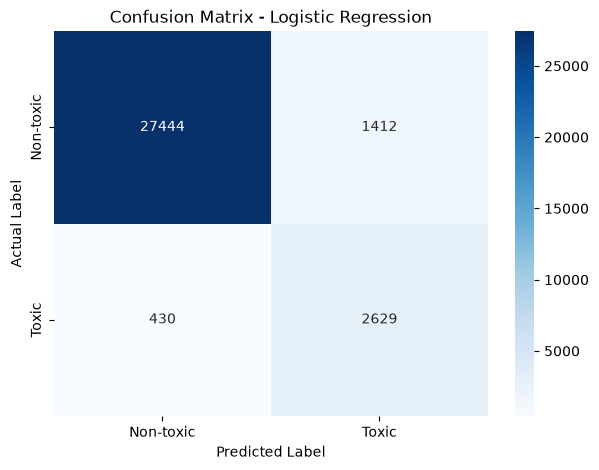


Classification Report:
              precision    recall  f1-score   support

   Non-toxic       0.98      0.95      0.97     28856
       Toxic       0.65      0.86      0.74      3059

    accuracy                           0.94     31915
   macro avg       0.82      0.91      0.85     31915
weighted avg       0.95      0.94      0.95     31915



In [8]:

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-toxic", "Toxic"],
    yticklabels=["Non-toxic", "Toxic"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

# Display detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Non-toxic", "Toxic"]
))

In [9]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Test different classification thresholds
thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

print("Threshold Comparison")
print("-" * 65)
print(f"{'Threshold':<12}{'Precision':<15}{'Recall':<15}{'F1-score':<15}")

for threshold in thresholds:

    # Convert probabilities into binary predictions
    y_pred_threshold = (y_prob >= threshold).astype(int)

    # Calculate evaluation metrics
    precision = precision_score(y_test, y_pred_threshold)
    recall = recall_score(y_test, y_pred_threshold)
    f1 = f1_score(y_test, y_pred_threshold)

    print(
        f"{threshold:<12.1f}"
        f"{precision:<15.4f}"
        f"{recall:<15.4f}"
        f"{f1:<15.4f}"
    )


Threshold Comparison
-----------------------------------------------------------------
Threshold   Precision      Recall         F1-score       
0.2         0.3586         0.9667         0.5231         
0.3         0.4685         0.9330         0.6238         
0.4         0.5677         0.8987         0.6959         
0.5         0.6506         0.8594         0.7406         
0.6         0.7345         0.8140         0.7722         
0.7         0.8030         0.7542         0.7778         
0.8         0.8719         0.6787         0.7632         


In [10]:

import pandas as pd

# Store the experimental results
threshold_results = pd.DataFrame({
    "Threshold": [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
    "Precision": [0.3586, 0.4685, 0.5677, 0.6506,
                  0.7345, 0.8030, 0.8719],
    "Recall": [0.9667, 0.9330, 0.8987, 0.8594,
               0.8140, 0.7542, 0.6787],
    "F1-score": [0.5231, 0.6238, 0.6959, 0.7406,
                 0.7722, 0.7778, 0.7632]
})

# Display results
threshold_results


,Threshold,Precision,Recall,F1-score
0,0.2,0.3586,0.9667,0.5231
1,0.3,0.4685,0.9330,0.6238
2,0.4,0.5677,0.8987,0.6959
3,0.5,0.6506,0.8594,0.7406
4,0.6,0.7345,0.8140,0.7722
5,0.7,0.8030,0.7542,0.7778
6,0.8,0.8719,0.6787,0.7632


In [12]:
threshold_results.to_csv(
    "../results/metrics/threshold_comparison.csv",
    index=False
)

In [13]:
import os

file_path = "../results/metrics/threshold_comparison.csv"

print("File exists:", os.path.exists(file_path))

File exists: True


## 10. Baseline Model Analysis

The TF-IDF + Logistic Regression model achieved an accuracy of 94.23% and an ROC-AUC of 0.9730.

For the positive class (Toxic), the model achieved a precision of 65.06%, a recall of 85.94%, and an F1-score of 74.06%.

The relatively high recall indicates that the model can identify most toxic comments. However, its lower precision suggests that some non-toxic comments are incorrectly classified as toxic.

The confusion matrix shows that the model correctly identified 2,629 toxic comments, while 430 toxic comments were misclassified as non-toxic.

Although the overall accuracy is high, the imbalanced class distribution means that accuracy alone is insufficient for evaluating model performance.

Overall, TF-IDF combined with Logistic Regression provides a useful baseline for the content moderation task.

In [14]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of TF-IDF features:", X_train_tfidf.shape[1])

Training samples: 127656
Testing samples: 31915
Number of TF-IDF features: 50000


In [15]:
import os
import pandas as pd

# Create a summary of baseline model results
baseline_metrics = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression"],
    "Training_Samples": [len(X_train)],
    "Testing_Samples": [len(X_test)],
    "TFIDF_Features": [X_train_tfidf.shape[1]],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1_Score": [f1],
    "ROC_AUC": [roc_auc]
})

# Save the results
os.makedirs("../results/metrics", exist_ok=True)

baseline_metrics.to_csv(
    "../results/metrics/baseline_metrics.csv",
    index=False
)

# Display the summary
baseline_metrics

,Model,Training_Samples,Testing_Samples,TFIDF_Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,TF-IDF + Logistic Regression,127656,31915,50000,0.942284,0.871903,0.678653,0.763235,0.973032


In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Recalculate metrics using the default threshold (0.5)
baseline_accuracy = accuracy_score(y_test, y_pred)
baseline_precision = precision_score(y_test, y_pred)
baseline_recall = recall_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred)
baseline_roc_auc = roc_auc_score(y_test, y_prob)

# Rebuild the baseline summary
baseline_metrics = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression"],
    "Training_Samples": [len(X_train)],
    "Testing_Samples": [len(X_test)],
    "TFIDF_Features": [X_train_tfidf.shape[1]],
    "Accuracy": [baseline_accuracy],
    "Precision": [baseline_precision],
    "Recall": [baseline_recall],
    "F1_Score": [baseline_f1],
    "ROC_AUC": [baseline_roc_auc]
})

# Save corrected results
baseline_metrics.to_csv(
    "../results/metrics/baseline_metrics.csv",
    index=False
)

baseline_metrics

,Model,Training_Samples,Testing_Samples,TFIDF_Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,TF-IDF + Logistic Regression,127656,31915,50000,0.942284,0.650582,0.859431,0.740563,0.973032


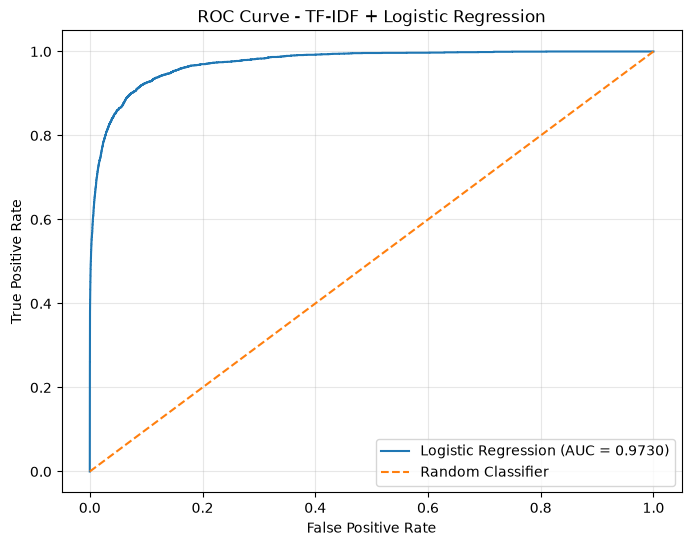

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import os

# Calculate ROC curve points
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
roc_auc_value = auc(fpr, tpr)

# Create the figure
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc_value:.4f})"
)

# Add random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - TF-IDF + Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

# Save the figure
os.makedirs("../results/figures", exist_ok=True)

plt.savefig(
    "../results/figures/baseline_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
from sklearn.metrics import precision_recall_curve, average_precision_score

In [20]:
# Calculate Precision-Recall values
precision_values, recall_values, thresholds_pr = precision_recall_curve(
    y_test,
    y_prob
)

# Calculate Average Precision
average_precision = average_precision_score(y_test, y_prob)

print("Average Precision:", round(average_precision, 4))
print("Number of Precision-Recall points:", len(precision_values))

Average Precision: 0.8669
Number of Precision-Recall points: 31684


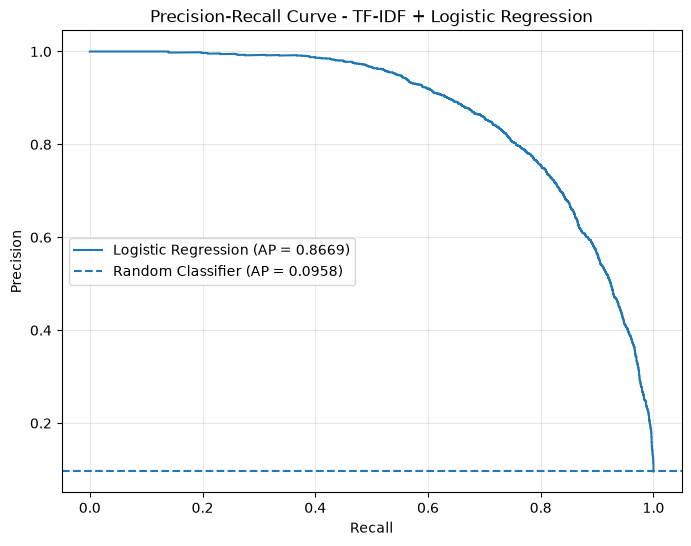

In [21]:
# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Logistic Regression (AP = {average_precision:.4f})"
)

# Baseline: proportion of positive samples
baseline = y_test.mean()

plt.axhline(
    y=baseline,
    linestyle="--",
    label=f"Random Classifier (AP = {baseline:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - TF-IDF + Logistic Regression")

plt.legend()
plt.grid(alpha=0.3)

# Save the figure
plt.savefig(
    "../results/figures/baseline_pr_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
# Add Average Precision to baseline metrics
baseline_metrics["Average_Precision"] = average_precision

# Save the updated metrics
baseline_metrics.to_csv(
    "../results/metrics/baseline_metrics.csv",
    index=False
)

baseline_metrics

,Model,Training_Samples,Testing_Samples,TFIDF_Features,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
0,TF-IDF + Logistic Regression,127656,31915,50000,0.942284,0.650582,0.859431,0.740563,0.973032,0.866931


## 11. Precision-Recall Analysis

The TF-IDF + Logistic Regression model achieved an Average Precision (AP) of 0.8669.

The Precision-Recall curve remains substantially above the random classifier baseline, indicating that the model can distinguish toxic comments from non-toxic comments effectively.

At lower recall levels, the model maintains high precision, suggesting that its high-confidence toxic predictions are generally reliable.

However, precision decreases as recall increases. This reflects the trade-off between identifying more toxic comments and avoiding false positive classifications.

The results demonstrate that the baseline model provides strong classification performance despite the imbalanced distribution of the dataset.